# Árboles de Decisión
**Módulos:** Sistemas de aprendizaje automático (SAA)   
**Curso:** 2025/26 - Curso Especialización en IA y Big Data - IES Ribera de Castilla

## 1. Concepto

Un **Árbol de Decisión** es un modelo de **aprendizaje supervisado** (utilizado tanto para clasificación como para regresión) que toma decisiones basándose en una estructura de grafo similar a un árbol.

El modelo aprende reglas de decisión simples (ej. "¿Es el `ingreso` > 50.000€?") inferidas a partir de las características de los datos.

La estructura se compone de:
- **Nodo Raíz (Root Node):** El nodo inicial que representa a toda la población de datos.
- **Nodos Internos (Internal Nodes):** Nodos donde se realiza una "pregunta" o se evalúa una característica para dividir los datos.
- **Ramas (Branches):** Representan el resultado de una decisión (ej. "Sí" o "No").
- **Nodos Hoja (Leaf Nodes):** Nodos terminales que representan el resultado final (una clase en clasificación, o un valor numérico en regresión).

El algoritmo busca en cada paso la mejor característica para dividir los datos, utilizando métricas como la **Impureza de Gini** o la **Ganancia de Información (Entropía)**.

El **índice Gini** es una medida de impureza o heterogeneidad utilizada para evaluar lo mezcladas que están las clases dentro de un nodo. Cuanto más homogéneo es un nodo, menor es su valor de Gini.    
Si todas las muestras pertenecen a una sola clase, el índice es 0, indicando pureza total. Durante la construcción del árbol, el algoritmo analiza todas las divisiones posibles y elige aquella que genera subgrupos más homogéneos, es decir, que más reduzca el valor de Gini. Esto permite que las decisiones del árbol sean más precisas, porque intenta que cada rama contenga datos lo más parecidos posible.

La **entropía** mide el grado de desorden o incertidumbre en un conjunto de datos. Si todas las muestras de un nodo son de la misma clase, la entropía es 0. Si hay una mezcla uniforme de clases, la entropía es máxima. Para decidir una división, el árbol calcula la ganancia de información, que es cuánto se reduce la entropía al dividir un nodo. Cuanto mayor es esta ganancia, mejor es la división. El objetivo es construir un árbol que reduzca progresivamente la incertidumbre y cree nodos cada vez más homogéneos.

*El algoritmo utiliza un único criterio de impureza (como Gini o entropía) para todo el árbol*. En cada paso, evalúa las posibles divisiones con ese criterio y elige la que más reduce la impureza de los grupos resultantes.

## 2. Características Principales

### Ventajas
* **Interpretabilidad (White Box):** Son muy fáciles de entender y visualizar. Se pueden explicar las decisiones tomadas ("es un modelo de caja blanca").
* **Mínimo preprocesamiento:** No requieren normalización o escalado de los datos.
* **Manejo de datos mixtos:** Pueden trabajar con características numéricas y categóricas (aunque la implementación de `scikit-learn` requiere que sean numéricas).
* **Selección de características implícita:** Los nodos superiores del árbol son intrínsecamente las características más importantes.

### Desventajas
* **Sobreajuste (Overfitting):** Tienden a crear árboles muy complejos que memorizan los datos de entrenamiento pero no generalizan bien a datos nuevos. Esto se controla con la **poda (pruning)** o limitando la profundidad máxima (`max_depth`).
* **Inestabilidad:** Pequeños cambios en los datos de entrada pueden generar un árbol completamente diferente.
* **Sesgo:** Tienden a favorecer características que tienen muchos niveles o valores.

### Puntos clave.     


● El árbol divide los datos en cada nodo aplicando condiciones simples sobre las características.     
● Utiliza un criterio de impureza (como Gini o entropía) para decidir la mejor división en cada paso.     
● Las divisiones se realizan de forma recursiva hasta cumplir una condición de parada o alcanzar nodos puros.     
● Cada hoja representa una clase final, y el camino desde la raíz hasta ella se interpreta como una secuencia de reglas.    
● El modelo puede volverse muy complejo si se deja crecer sin límites, lo que lleva a sobreajuste.     
● No necesita normalizar ni escalar las variables, ya que trabaja directamente con los valores.     
● Es sensible a pequeñas variaciones en los datos, lo que puede cambiar mucho la estructura del árbol.     
● Es un modelo fácilmente interpretable, ideal cuando se busca explicar las decisiones del sistema.


### Hiperparámetros del algoritmo   

Los árboles de decisión permiten ajustar su comportamiento a través de varios hiperparámetros que controlan su crecimiento y evitan el sobreajuste. Los más relevantes son:

● `max_depth`, que limita la profundidad máxima del árbol.    
● `min_samples_split`, que define el número mínimo de muestras para dividir un nodo.    
● `min_samples_leaf`, que exige un número mínimo de muestras en cada hoja.    
● `max_features`, que limita cuántas características se consideran en cada división.     
● `max_leaf_nodes`, que restringe el número total de hojas del árbol.     
● `min_impurity_decrease`, que impone una reducción mínima de impureza para aceptar una división.      
● `criterion`, que define la función para medir la calidad de una división (`gini` o `entropy`).

Ajustar estos parámetros permite controlar el equilibrio entre la precisión y la capacidad de generalización del modelo. Un árbol con pocos límites tiende a memorizar los datos, mientras que uno demasiado restringido puede no captar patrones importantes.

Los árboles *no necesitan escalar los datos ni hacer transformaciones previas*. Un árbol solo compara cada variable con un umbral (por ejemplo, `bill_length_mm <= 42.3`), así que da igual que una variable vaya de 0 a 1 y otra de 0 a 5000. *El resultado es el mismo con o sin escalar*, y lo mismo vale para Random Forest y Gradient Boosting.

Funcionan bien con datos numéricos y categóricos, y su estructura basada en reglas los hace fáciles de entender. Sin embargo, son sensibles a pequeñas variaciones en los datos y pueden cambiar mucho con pocas muestras diferentes, por eso se suelen usar junto con métodos como los bosques aleatorios para ganar estabilidad.

## 3. Usos y Aplicaciones Habituales

Los árboles de decisión son muy comunes en problemas donde la interpretabilidad es clave:

**Clasificación:**
* **Diagnóstico Médico:** (ej. ¿Tiene el paciente gripe basado en síntomas?).
* **Análisis de Riesgo Crediticio:** (ej. ¿Se debe aprobar un préstamo?).
* **Filtro de Spam.**

**Regresión:**
* **Predicción de precios:** (ej. Estimar el precio de una vivienda).
* **Estimación de demanda.**

### Cuándo es aconsejable o no su uso    

Los árboles de decisión funcionan especialmente bien cuando *las clases se pueden separar mediante reglas simples basadas en condiciones sobre las características*. Son útiles *cuando hay variables categóricas o combinaciones lógicas claras*, y cuando se busca un *modelo interpretable y fácil de explicar*. También se adaptan bien a *conjuntos con ruido moderado y sin requerimientos de escalado*.

En cambio, no funcionan tan bien cuando los límites entre clases son curvos o muy complejos, ya que las divisiones son siempre rectas y paralelas a los ejes. También *tienden a sobreajustar si se les deja crecer sin control*, sobre todo cuando hay mucho ruido o pocos datos. En problemas con muchas variables irrelevantes o correlacionadas, el árbol puede volverse inestable y difícil de generalizar.

## 4. Ejemplos con Python y Scikit-learn

Vamos a implementar los dos tipos de árboles (Clasificación y Regresión) usando las librerías que vemos en el módulo de PIA[cite: 188].

### Ejemplo 1: Clasificación con `DecisionTreeClassifier` (Dataset Iris)

El objetivo es clasificar una flor de iris en una de sus tres especies (Setosa, Versicolor, Virginica) basándose en la longitud y anchura de sus pétalos y sépalos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# 1. Cargar datos
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print("Features (X):")
print(X.head())
print("\nTarget (y) (0=Setosa, 1=Versicolor, 2=Virginica):")
print(y[:5])

Features (X):
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target (y) (0=Setosa, 1=Versicolor, 2=Virginica):
[0 0 0 0 0]


In [3]:
# 2. Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [4]:
# 3. Crear y entrenar el modelo
# Usamos max_depth=3 para prevenir el sobreajuste y hacerlo interpretable.
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
clf.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [5]:
# 4. Evaluar el modelo
y_pred = clf.predict(X_test)

print(f"Accuracy (Precisión): {accuracy_score(y_test, y_pred):.2f}")
print("\nMatriz de Confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy (Precisión): 1.00

Matriz de Confusión:
[[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]

Reporte de Clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



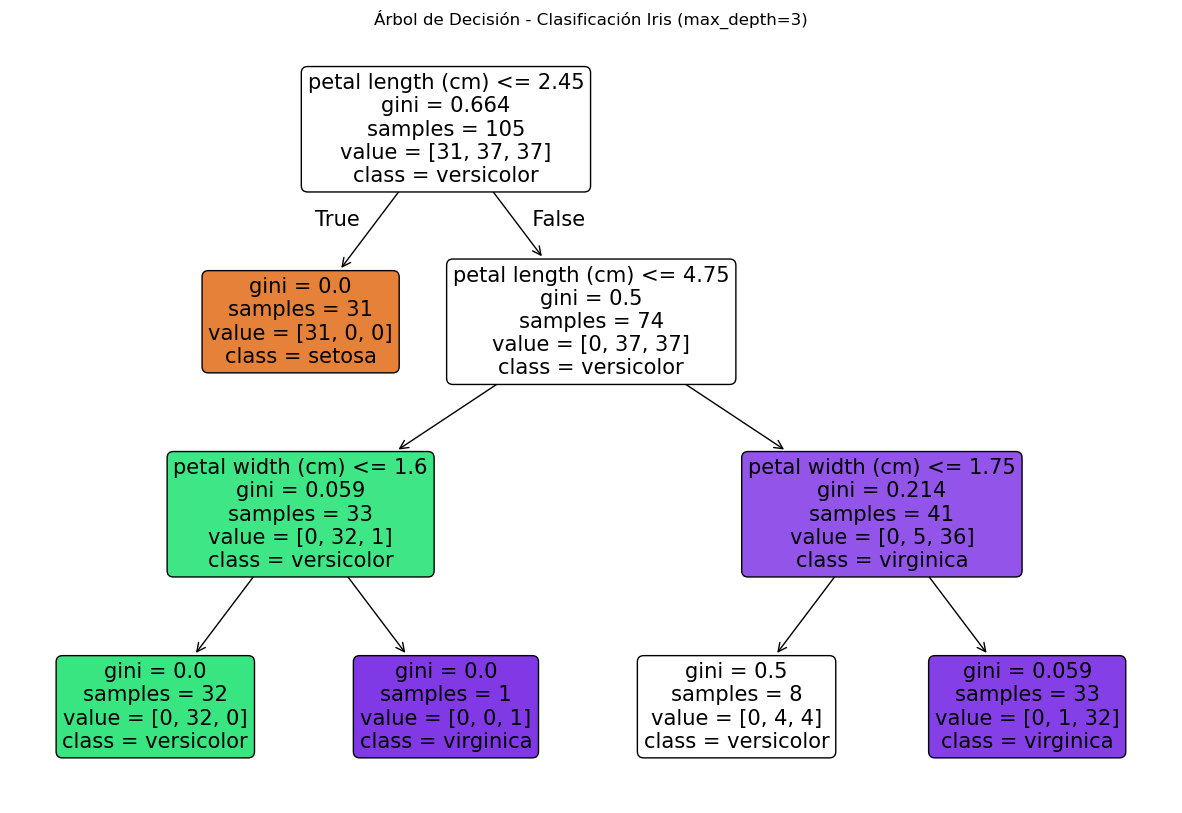

In [6]:
# 5. Visualizar el árbol
plt.figure(figsize=(15, 10))
plot_tree(clf,
          filled=True,      # Colorea los nodos
          rounded=True,     # Nodos con bordes redondeados
          class_names=iris.target_names, # Nombres de las clases (target)
          feature_names=iris.feature_names) # Nombres de las características (features)
plt.title("Árbol de Decisión - Clasificación Iris (max_depth=3)")
plt.show()

### Ejemplo 2: Regresión con `DecisionTreeRegressor` (Dataset Diabetes)

El objetivo es predecir una medida cuantitativa de la progresión de la diabetes un año después, basándose en 10 variables (edad, sexo, bmi, presión arterial, etc.).

In [7]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [8]:
# 1. Cargar datos
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

print("Features (X):")
print(X.head())
print("\nTarget (y) (Progresión de la diabetes):")
print(y[:5])

Features (X):
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Target (y) (Progresión de la diabetes):
[151.  75. 141. 206. 135.]


In [9]:
# 2. Dividir
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [10]:
# 3. Crear y entrenar el modelo
# En regresión, el criterio suele ser 'squared_error'
reg = DecisionTreeRegressor(criterion='squared_error', max_depth=4, random_state=42)
reg.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [11]:
# 4. Evaluar
y_pred_reg = reg.predict(X_test)

mse = mean_squared_error(y_test, y_pred_reg)
r2 = r2_score(y_test, y_pred_reg)

print(f"Error Cuadrático Medio (MSE): {mse:.2f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {np.sqrt(mse):.2f}")
print(f"Coeficiente R2: {r2:.2f}")

Error Cuadrático Medio (MSE): 3649.42
Raíz del Error Cuadrático Medio (RMSE): 60.41
Coeficiente R2: 0.32


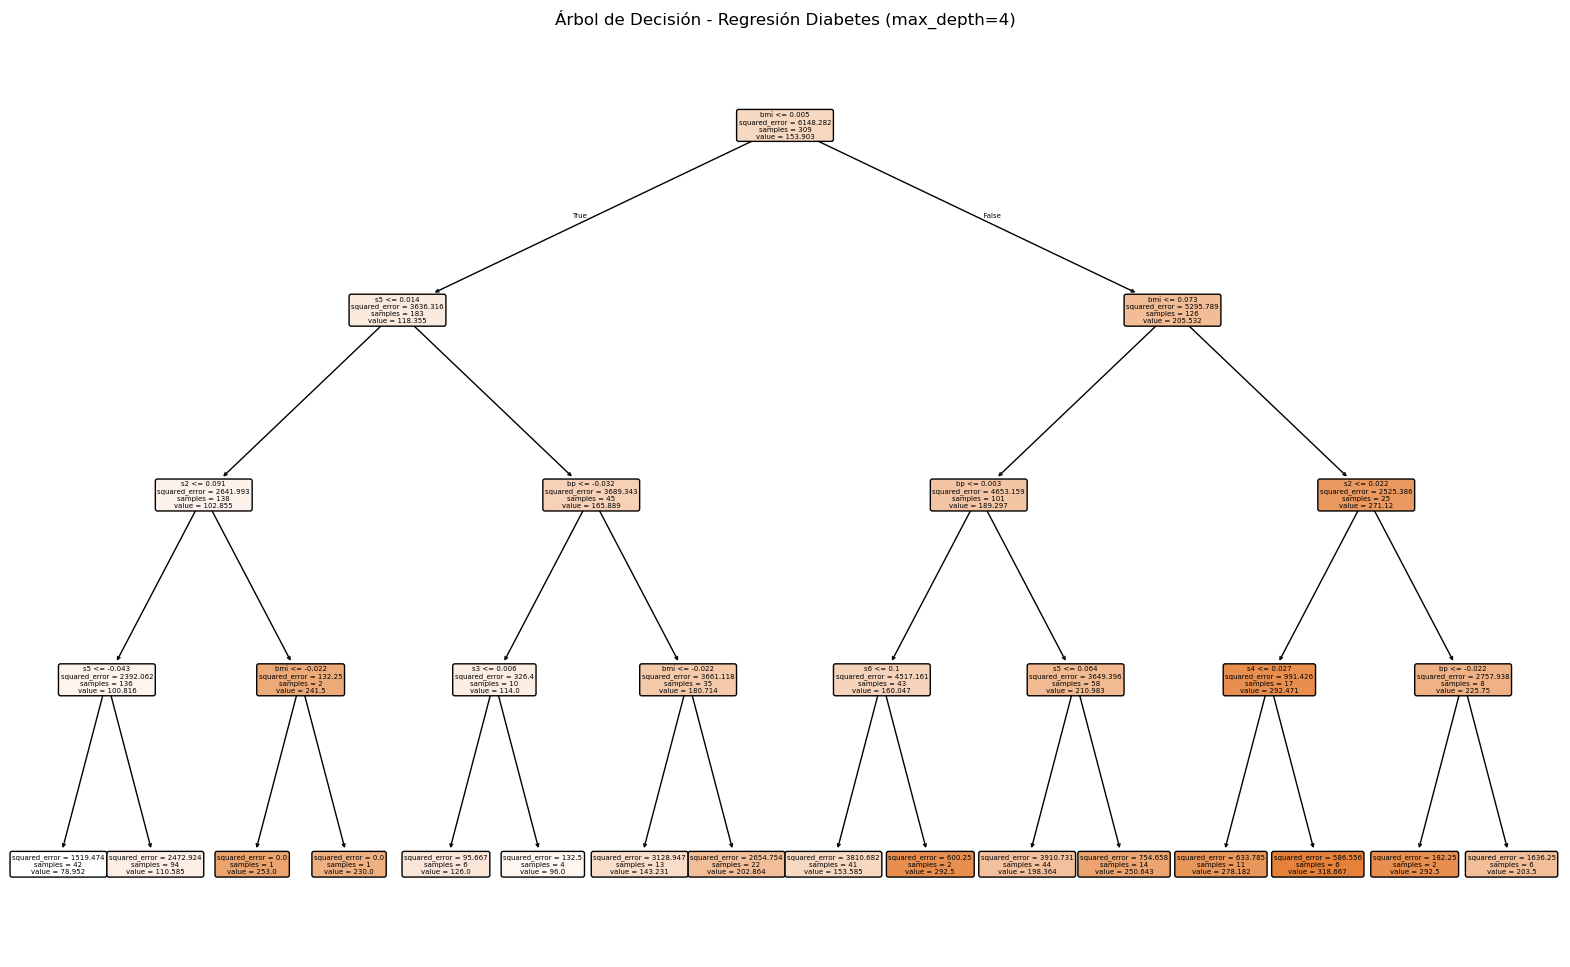

In [12]:
# 5. Visualizar (Regresión)
# Nota: En regresión, el 'value' en la hoja es el valor medio predicho para ese grupo.
plt.figure(figsize=(20, 12))
plot_tree(reg,
          filled=True,
          rounded=True,
          feature_names=diabetes.feature_names)
plt.title("Árbol de Decisión - Regresión Diabetes (max_depth=4)")
plt.show()

### Buscando el nodo hijo más puro...   

Que el algoritmo intente producir "nodos hijos lo más puros posibles" significa que busca encontrar la "pregunta" (la división de los datos) que mejor separe las clases en grupos homogéneos.

Imaginar que tenemos una baraja de cartas mezclada (ese es el nodo raíz, muy "impuro" porque tiene las 4 palos).

El objetivo del algoritmo es encontrar la pregunta que mejor las separe:
- Pregunta A (Mala): "¿Es la carta un 7?"
    - Nodo Hijo 1 (Sí): Tendrás 4 cartas (el 7 de Picas, 7 de Corazones, 7 de Diamantes, 7 de Tréboles). Sigue siendo un nodo muy impuro (mezclado).

    - Nodo Hijo 2 (No): Tendrás el resto de la baraja. Sigue siendo muy impuro.

- Pregunta B (Buena): "¿Es la carta de color rojo?"
    - Nodo Hijo 1 (Sí): Tendrás solo Corazones y Diamantes. Este nodo es más puro que el nodo original (la baraja entera), ya que hemos eliminado las Picas y los Tréboles

    - Nodo Hijo 2 (No): Tendrás solo Picas y Tréboles. Este nodo también es más puro.

El algoritmo de Árbol de Decisión, al "buscar la pureza", elegirá automáticamente la Pregunta B.


## EJERCICIO - Clasifica a los pingüinos de Palmer usando el algoritmo de *árbol de decisión*.


En este problema el objetivo es predecir **la especie de pingüino** según los datos del conjunto de datos de *pingüinos de Palmer*. Estos son los pingüinos:
<center><img src='./img/ThreePenguinSpecies (1).png'></center>

El conjunto de datos completo contiene una combinación de atributos numéricos (por ejemplo, `bill_depth_mm`), categóricos (por ejemplo, `island`) y faltantes. 

***Nota sobre scikit-learn y versiones***    

Para árboles de decisión, desde la versión 1.3 `DecisionTreeClassifier` y `DecisionTreeRegressor` aceptan valores nulos (NaN) directamente: durante el entrenamiento deciden hacia qué rama enviar los nulos en cada división. `RandomForestClassifier` los admite desde la 1.4, y `HistGradientBoostingClassifier` desde hace bastante más.    

Respecto al tratamiento de variables categóricas, a pesar de que los árboles de decisión teóricamente trabajan con ellas, la implementación de `scikit-learn` **solo acepta números**, por lo que se vuelve necesario codificar esas columnas antes de entrenar.


#### Sugerencia

Si quieres probar una librería que se `acerca más` al comportamiento teórico de los árboles de decisión, intenta con la librería [`YDG`](https://ydf.readthedocs.io/en/latest/tutorial/getting_started/) 

Para instalar la librería:   
```
    !pip install ydf -U
```


Para usar un único árbol en tu modelo:    
```python
    model = ydf.CartLearner(label=label).train(train_dataset)
```


### 1. Carga del dataset

In [13]:
path = "./datasets/penguins.csv"
dataset = pd.read_csv(path)
label = "species"

# Echar un vistazo a los primeros registros
dataset.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
